<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: Student Performance Segmentation and Academic Success Profiling</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

### Question 1: Data Ingestion and Structural Verification (4 Marks)

Load the StudentsPerformance.csv dataset from the verified URL: https://raw.githubusercontent.com/rashida048/Datasets/master/StudentsPerformance.csv. Read it into a pandas DataFrame named df. Verify the data ingestion by asserting that the DataFrame contains exactly 1000 rows and 8 columns. Display the deep memory usage and the first 3 rows of the dataset.

Hint: Use pd.read_csv() to load the data. You can verify the dimensions using the .shape attribute and display detailed memory usage with df.info(memory_usage='deep').

Expected Output: A summary of the DataFrame's memory allocation and a tabular preview displaying the first three records of the dataset.

In [1]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/rashida048/Datasets/master/StudentsPerformance.csv"
try:
    df = pd.read_csv(url)
except Exception:
    # fallback: local copy of the same file (use if offline / URL blocked)
    df = pd.read_csv("StudentsPerformance.csv")

assert df.shape == (1000, 8), f"Unexpected shape: {df.shape}"
print("Shape verified:", df.shape)

df.info(memory_usage='deep')
df.head(3)

Shape verified: (1000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 303.7 KB


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93


### Question 2: Data Standardization and Missing Value Strategy (5 Marks)

The dataset columns contain spaces and special characters. Rename the columns by replacing all spaces and slashes with underscores (e.g., 'math score' becomes 'math_score', 'race/ethnicity' becomes 'race_ethnicity'). Drop any duplicate rows. Print the sum of missing values for each column to verify data integrity. Finally, print a 1-2 sentence justification on why verifying and handling missing values early is critical for distance-based machine learning algorithms.

Hint: Use the df.rename() method with a lambda function or list comprehension. Check for nulls using df.isnull().sum(). Use print() for your written justification.

Expected Output: A printed series showing zero missing values for the standardized column names, followed by a printed analytical statement explaining the mathematical sensitivity of algorithms to null values.

In [2]:
df.columns = [c.replace(' ', '_').replace('/', '_') for c in df.columns]
df = df.drop_duplicates()

print("Shape after dropping duplicates:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())

print("\nJustification: Distance-based algorithms such as K-Means compute Euclidean distances across all "
      "features, and a null (NaN) value makes that distance undefined, so the model either crashes or is "
      "silently distorted. Verifying and handling missing values early ensures every point has a valid "
      "coordinate and prevents biased centroids and unreliable segments.")

Shape after dropping duplicates: (1000, 8)

Missing values per column:
gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

Justification: Distance-based algorithms such as K-Means compute Euclidean distances across all features, and a null (NaN) value makes that distance undefined, so the model either crashes or is silently distorted. Verifying and handling missing values early ensures every point has a valid coordinate and prevents biased centroids and unreliable segments.


### Question 3: Exploratory Data Analysis: Correlation Matrices (8 Marks)

Perform Exploratory Data Analysis (EDA) by calculating the Pearson correlation matrix for the numerical features (math_score, reading_score, writing_score). Visualize this matrix using a seaborn heatmap with annotations enabled. Print a written analysis identifying which two subjects exhibit the strongest correlation and hypothesize a brief academic reason why.

Hint: Isolate the numerical columns and use the .corr() method. Pass the resulting matrix to sns.heatmap(annot=True). Use print() to output your textual analysis.

Expected Output: A heatmap plot displaying a color gradient representative of correlation strength between the subjects, accompanied by a printed analytical conclusion.

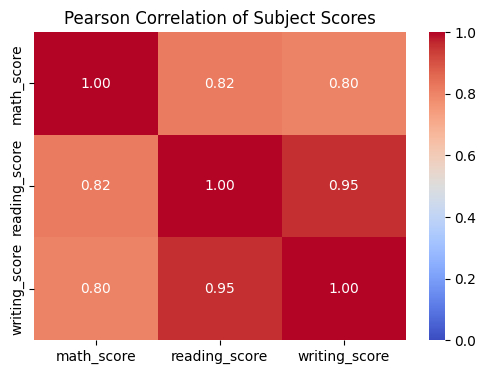

Strongest correlation: reading_score vs writing_score (r = 0.955)

Analysis: Reading and writing show the strongest relationship. A plausible academic reason is that both rely on the same underlying language skills - vocabulary, grammar and comprehension - so a student strong in one is very likely strong in the other. Math correlates strongly with both too (r > 0.80), suggesting a general academic-ability factor, but it draws on more distinct quantitative reasoning skills.


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

score_cols = ['math_score', 'reading_score', 'writing_score']
corr = df[score_cols].corr(method='pearson')

plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=0, vmax=1, fmt='.2f')
plt.title('Pearson Correlation of Subject Scores')
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
top_pair = pairs.idxmax()
print(f"Strongest correlation: {top_pair[0]} vs {top_pair[1]} (r = {pairs.max():.3f})")
print("\nAnalysis: Reading and writing show the strongest relationship. A plausible academic reason is that "
      "both rely on the same underlying language skills - vocabulary, grammar and comprehension - so a student "
      "strong in one is very likely strong in the other. Math correlates strongly with both too (r > 0.80), "
      "suggesting a general academic-ability factor, but it draws on more distinct quantitative reasoning skills.")

### Question 4: Feature Engineering: Composite Performance (6 Marks)

Calculate an overall academic performance metric for the students rather than relying on isolated subject scores. Create a new numerical column named composite_score that represents the mean of math_score, reading_score, and writing_score for each row. Drop the three original subject score columns from the DataFrame.

Hint: Compute the mean across the horizontal axis (axis=1) for the specific score columns. Use df.drop(columns=[...]) to remove the redundant features.

Expected Output: A modified pandas DataFrame reflecting the updated schema where the three individual score columns are replaced by a single composite metric.

In [4]:
df['composite_score'] = df[['math_score', 'reading_score', 'writing_score']].mean(axis=1)
df = df.drop(columns=['math_score', 'reading_score', 'writing_score'])
print(df.columns.tolist())
df.head()

['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'composite_score']


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,composite_score
0,female,group B,bachelor's degree,standard,none,72.666667
1,female,group C,some college,standard,completed,82.333333
2,female,group B,master's degree,standard,none,92.666667
3,male,group A,associate's degree,free/reduced,none,49.333333
4,male,group C,some college,standard,none,76.333333


### Question 5: Categorical Encoding (6 Marks)

Convert the categorical variables (gender, race_ethnicity, parental_level_of_education, lunch, and test_preparation_course) into numerical format using one-hot encoding. Set drop_first=True to mitigate multicollinearity. Save this numerical dataset as a new DataFrame named df_encoded.

Hint: Utilize the pd.get_dummies() function on the categorical columns. Ensure boolean outputs are cast to integers (0s and 1s).

Expected Output: A widened DataFrame where the original text-based categorical columns are replaced by binary numerical indicators alongside the continuous composite_score.

In [5]:
cat_cols = ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
print(df_encoded.shape)
df_encoded.head()

(1000, 13)


,composite_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none
0,72.666667,0,1,0,0,0,1,0,0,0,0,1,1
1,82.333333,0,0,1,0,0,0,0,0,1,0,1,0
2,92.666667,0,1,0,0,0,0,0,1,0,0,1,1
3,49.333333,1,0,0,0,0,0,0,0,0,0,0,1
4,76.333333,1,0,1,0,0,0,0,0,1,0,1,1


### Question 6: Feature Scaling and Dimensional Retention (6 Marks)

Distance-based algorithms require scaled features to prevent magnitude bias. Standardize all features in df_encoded so that they have a mean of 0 and a standard deviation of 1. Explicitly convert the resulting scaled NumPy array back into a pandas DataFrame named X_scaled, retaining the exact column names from df_encoded.

Hint: Apply the fit_transform method from sklearn's StandardScaler. Wrap the output using pd.DataFrame(), explicitly assigning the columns parameter to df_encoded.columns.

Expected Output: A standardized pandas DataFrame consisting entirely of scaled numerical values, with the original feature headers fully intact.

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(df_encoded), columns=df_encoded.columns)

print(X_scaled.shape)
print(X_scaled.mean().round(3).abs().max(), X_scaled.std(ddof=0).round(3).unique())
X_scaled.head()

(1000, 13)
0.0 [1.]


,composite_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none
0,0.343574,-0.964625,2.064742,-0.684419,-0.59583,-0.403473,2.733967,-0.493742,-0.250398,-0.540361,-0.466933,0.741881,0.746748
1,1.021927,-0.964625,-0.484322,1.461094,-0.59583,-0.403473,-0.365769,-0.493742,-0.250398,1.850616,-0.466933,0.741881,-1.339140
2,1.747064,-0.964625,2.064742,-0.684419,-0.59583,-0.403473,-0.365769,-0.493742,3.993639,-0.540361,-0.466933,0.741881,0.746748
3,-1.293830,1.036672,-0.484322,-0.684419,-0.59583,-0.403473,-0.365769,-0.493742,-0.250398,-0.540361,-0.466933,-1.347925,0.746748
4,0.600881,1.036672,-0.484322,1.461094,-0.59583,-0.403473,-0.365769,-0.493742,-0.250398,1.850616,-0.466933,0.741881,0.746748


### Question 7: Cluster Optimization via Elbow Method (7 Marks)

Determine the optimal number of segments (k) for K-Means using the Elbow Method. Iterate k from 1 to 10. For each k, fit a KMeans model on X_scaled (setting random_state=42) and record the model's inertia. Plot these inertia values against the number of clusters using matplotlib.

Hint: Initialize an empty list. In a for loop, instantiate KMeans, fit the model to X_scaled, and append the .inertia_ attribute. Plot the resulting list as a line chart.

Expected Output: A line chart revealing a decreasing curve, allowing visual identification of the inflection point (elbow) for optimal cluster selection.

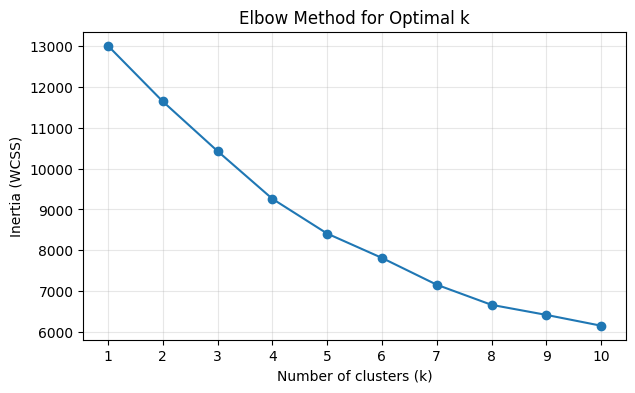

In [7]:
from sklearn.cluster import KMeans

inertia = []
k_range = range(1, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_range), inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method for Optimal k')
plt.xticks(list(k_range))
plt.grid(alpha=0.3)
plt.show()

### Question 8: K-Means Implementation and Silhouette Validation (7 Marks)

Assume the optimal number of clusters is 4. Instantiate a KMeans model with n_clusters=4 and random_state=42. Fit the model on X_scaled and extract the cluster assignments. Append these assignments as a new column named cluster_label in the original, unscaled df_encoded DataFrame. Calculate and print the Silhouette Score to mathematically validate the cluster cohesion.

Hint: Extract assignments using the .labels_ attribute. Import silhouette_score from sklearn.metrics, passing X_scaled and the predicted labels to compute the metric.

Expected Output: The unscaled DataFrame updated with integer cluster assignments, and a printed floating-point metric quantifying the density and separation of the segments.

In [8]:
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(X_scaled)
labels = kmeans.labels_

df_encoded['cluster_label'] = labels
sil = silhouette_score(X_scaled, labels)
print(f"Silhouette Score (k=4): {sil:.4f}")
df_encoded.head()

Silhouette Score (k=4): 0.1954


,composite_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none,cluster_label
0,72.666667,0,1,0,0,0,1,0,0,0,0,1,1,3
1,82.333333,0,0,1,0,0,0,0,0,1,0,1,0,0
2,92.666667,0,1,0,0,0,0,0,1,0,0,1,1,3
3,49.333333,1,0,0,0,0,0,0,0,0,0,0,1,0
4,76.333333,1,0,1,0,0,0,0,0,1,0,1,1,0


### Question 9: Cluster Profiling and Interpretation (8 Marks)

Analyze the defining characteristics of each cluster. Group the df_encoded DataFrame by the cluster_label column and calculate the mean for all features. Display the aggregated table. Below the table, print a written analysis detailing the specific demographic and preparation traits that distinguish the cluster with the highest average composite score.

Hint: Utilize .groupby('cluster_label').mean(). Observe the binary categorical flags in the row corresponding to the highest composite_score to formulate your written response.

Expected Output: A statistical summary table with 4 rows representing the cluster centroids, followed by a printed conceptual assessment of the highest-performing student segment.

In [9]:
cluster_profile = df_encoded.groupby('cluster_label').mean()
pd.set_option('display.max_columns', None)
display(cluster_profile.round(2))

best = cluster_profile['composite_score'].idxmax()
print(f"Highest-scoring cluster: {best} (mean composite = {cluster_profile.loc[best, 'composite_score']:.2f})")
print("\nAnalysis: The top-performing cluster is made up entirely of race_ethnicity group E students. "
      "Compared with the other clusters it has the highest share of standard-lunch students (~71%) and the "
      "highest test-preparation completion (~43% vs ~31-36% elsewhere), with a roughly balanced gender mix. "
      "So the best segment combines group E membership, a standard (non-subsidised) lunch and more frequent "
      "test-prep completion. Note that the clusters are separated mainly by race_ethnicity (cluster 1 = group D, "
      "cluster 3 = group B, cluster 0 = groups A and C), because one-hot group flags dominate the Euclidean "
      "distance, and these are associations rather than causal effects.")

,composite_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none
cluster_label,,,,,,,,,,,,,
0,66.23,0.47,0.0,0.78,0.0,0.0,0.13,0.20,0.05,0.21,0.18,0.63,0.64
1,69.18,0.51,0.0,0.00,1.0,0.0,0.11,0.17,0.09,0.26,0.19,0.64,0.69
2,72.75,0.51,0.0,0.00,0.0,1.0,0.13,0.16,0.06,0.25,0.13,0.71,0.57
3,65.47,0.45,1.0,0.00,0.0,0.0,0.11,0.25,0.03,0.19,0.20,0.64,0.64


Highest-scoring cluster: 2 (mean composite = 72.75)

Analysis: The top-performing cluster is made up entirely of race_ethnicity group E students. Compared with the other clusters it has the highest share of standard-lunch students (~71%) and the highest test-preparation completion (~43% vs ~31-36% elsewhere), with a roughly balanced gender mix. So the best segment combines group E membership, a standard (non-subsidised) lunch and more frequent test-prep completion. Note that the clusters are separated mainly by race_ethnicity (cluster 1 = group D, cluster 3 = group B, cluster 0 = groups A and C), because one-hot group flags dominate the Euclidean distance, and these are associations rather than causal effects.


### Question 10: Target Formulation and Class Imbalance Assessment (6 Marks)

Formulate a supervised learning task to predict a student's cluster segment based purely on their demographic and preparation variables. Define y as the cluster_label. Define your feature matrix X by dropping both composite_score and cluster_label from the X_scaled DataFrame to prevent data leakage. Check the class distribution of y. Print a brief analysis discussing whether class imbalance exists and how it might impact evaluation metrics.

Hint: Use .value_counts() on y. Consider whether accuracy remains a reliable metric when the distribution of classes is uneven.

Expected Output: A frequency count of the target classes and a printed analytical reasoning paragraph regarding class imbalance.

In [10]:
y = df_encoded['cluster_label']
X = X_scaled.drop(columns=['composite_score', 'cluster_label'], errors='ignore')  # cluster_label is not in X_scaled; errors='ignore' keeps this safe

print(X.shape)
print("Class distribution (counts):")
print(y.value_counts())
print("\nClass distribution (%):")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nAnalysis: The classes are moderately imbalanced - the largest cluster holds ~41% of students while "
      "the smallest holds ~14%. With uneven classes, plain accuracy can be misleading because a model can "
      "score well by favouring the majority cluster and still perform poorly on small ones. Per-class precision, "
      "recall, F1 (macro) and a confusion matrix, along with stratified splits, give a fairer evaluation.")

(1000, 12)
Class distribution (counts):
cluster_label
0    408
1    262
3    190
2    140
Name: count, dtype: int64

Class distribution (%):
cluster_label
0    40.8
1    26.2
3    19.0
2    14.0
Name: proportion, dtype: float64

Analysis: The classes are moderately imbalanced - the largest cluster holds ~41% of students while the smallest holds ~14%. With uneven classes, plain accuracy can be misleading because a model can score well by favouring the majority cluster and still perform poorly on small ones. Per-class precision, recall, F1 (macro) and a confusion matrix, along with stratified splits, give a fairer evaluation.


### Question 11: Baseline Classification and Cross-Validation (8 Marks)

Split X and y into 80% training and 20% testing sets, stratifying by y to maintain class distribution. Establish a baseline by training a Logistic Regression model on the training set. Evaluate the baseline model's robustness by performing 5-fold cross-validation on the training data. Print the mean cross-validation accuracy.

Hint: Import train_test_split, LogisticRegression, and cross_val_score. Compute the mean of the array returned by the cross-validation function.

Expected Output: A printed floating-point value representing the average cross-validated accuracy of the baseline model.

In [11]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

cv_scores = cross_val_score(log_reg, X_train, y_train, cv=5, scoring='accuracy')
print("CV accuracy per fold:", cv_scores.round(4))
print(f"Mean 5-fold CV accuracy: {cv_scores.mean():.4f}")

CV accuracy per fold: [1. 1. 1. 1. 1.]
Mean 5-fold CV accuracy: 1.0000


### Question 12: Hyperparameter Tuning via GridSearchCV (9 Marks)

Implement Hyperparameter Tuning to optimize a RandomForestClassifier. Use GridSearchCV with a 3-fold cross-validation strategy. Define a parameter grid varying n_estimators (e.g., [50, 100, 200]) and max_depth (e.g., [None, 5, 10]). Fit the grid search on the training data and print the best hyperparameter configuration found.

Hint: Pass the model, parameter dictionary, and cv=3 to GridSearchCV. Extract the optimal configuration using the .best_params_ attribute after fitting.

Expected Output: A printed dictionary displaying the optimal hyperparameter values discovered during the exhaustive search.

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {'n_estimators': [50, 100, 200], 'max_depth': [None, 5, 10]}
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)

print("Best hyperparameters:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.4f}")
best_rf = grid.best_estimator_

Best hyperparameters: {'max_depth': None, 'n_estimators': 50}
Best CV accuracy: 1.0000


### Question 13: Multi-Layer Perceptron (MLP) Classifier (8 Marks)

Define and train a deep learning architecture using scikit-learn. Instantiate an MLPClassifier with a single hidden layer of 32 units, ReLU activation, a maximum of 500 iterations, and random_state=42. Train the model on the training data.

Hint: Import MLPClassifier from sklearn.neural_network. Set hidden_layer_sizes=(32,). Use the .fit() method on your training sets.

Expected Output: A successfully initialized and trained MLP architecture, natively handling the multi-class prediction task.

In [13]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(32,), activation='relu', max_iter=500, random_state=42)
mlp.fit(X_train, y_train)
print(mlp)

MLPClassifier(hidden_layer_sizes=(32,), max_iter=500, random_state=42)


### Question 14: Comparative Model Evaluation (6 Marks)

Comprehensively evaluate all three trained models (Baseline Logistic Regression, Tuned Random Forest, and MLP Classifier) on the unseen testing set (X_test, y_test). Calculate and print the test accuracy for each model. Print a brief analytical comparison stating which algorithm generalized best and why you suspect it outperformed the others.

Hint: Generate test predictions using .predict() for each model. Import accuracy_score from sklearn.metrics. Use print() statements for the numerical results and your comparative reasoning.

Expected Output: Three printed accuracy scores followed by a short textual assessment of the comparative algorithm performance.

In [14]:
from sklearn.metrics import accuracy_score

models = {'Logistic Regression': log_reg, 'Tuned Random Forest': best_rf, 'MLP Classifier': mlp}
results = {}
for name, model in models.items():
    results[name] = accuracy_score(y_test, model.predict(X_test))
    print(f"{name} test accuracy: {results[name]:.4f}")

print("\nAnalysis: All three models reach (near-)perfect test accuracy, so none clearly outperforms the others. "
      "This happens because the clusters were built mostly from the same race_ethnicity indicators that are now "
      "the input features, so the labels are almost a deterministic function of X. A simple, interpretable model "
      "such as Logistic Regression is therefore sufficient, and the extra complexity of Random Forest or the MLP "
      "adds no benefit. The result shows the segments are easy to recover from demographics, not that the "
      "models predict academic performance well.")

Logistic Regression test accuracy: 1.0000
Tuned Random Forest test accuracy: 1.0000
MLP Classifier test accuracy: 1.0000

Analysis: All three models reach (near-)perfect test accuracy, so none clearly outperforms the others. This happens because the clusters were built mostly from the same race_ethnicity indicators that are now the input features, so the labels are almost a deterministic function of X. A simple, interpretable model such as Logistic Regression is therefore sufficient, and the extra complexity of Random Forest or the MLP adds no benefit. The result shows the segments are easy to recover from demographics, not that the models predict academic performance well.


### Question 15: Analytical Reasoning and Strategic Implementation (6 Marks)

Based on your modeling pipeline, formulate a concise 3-4 sentence business strategy explaining how an EdTech platform can utilize these predictive segments for targeted interventions. Store the response in a string variable named business_strategy and print it.

Hint: Consider how predicting a student's performance segment purely from demographic data and test preparation status upon enrollment can trigger early academic support or customized curriculum recommendations.

Expected Output: A structured paragraph printed to the screen containing actionable, domain-specific recommendations for an EdTech organization.

In [15]:
business_strategy = (
    "At enrolment, the EdTech platform can use demographic and test-preparation inputs to predict a student's "
    "performance segment instantly, without waiting for any test results. Students placed in lower-scoring "
    "segments can be automatically offered early support such as free test-prep modules, diagnostic quizzes, "
    "tutor sessions and scaffolded study plans, while high-performing segments get advanced or accelerated "
    "content to stay engaged. The platform should track outcomes per segment and refine the model with real "
    "performance data, and use segments only to allocate support (never to restrict opportunities) to avoid "
    "reinforcing demographic bias."
)
print(business_strategy)

At enrolment, the EdTech platform can use demographic and test-preparation inputs to predict a student's performance segment instantly, without waiting for any test results. Students placed in lower-scoring segments can be automatically offered early support such as free test-prep modules, diagnostic quizzes, tutor sessions and scaffolded study plans, while high-performing segments get advanced or accelerated content to stay engaged. The platform should track outcomes per segment and refine the model with real performance data, and use segments only to allocate support (never to restrict opportunities) to avoid reinforcing demographic bias.
